# 2 · Measuring relatedness from links (Milne & Witten, 2008)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed"
SEED = "Hundred Years' War"
BLUE, GRAY = "#2a78d6", "#b9b8b1"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

> ✏️ **[Your text]** Why links, not text? (Relatedness vs similarity: Crécy ~ Edward III vs Crécy ~ Gettysburg.)

Two measures for a pair of articles $a, b$:

- **Out-links** (what both articles link to): cosine similarity of their link vectors, each link weighted by $\log(N / \text{df})$, like TF-IDF.
- **In-links** (what links to both, from all of Wikipedia, $W$ = 7.2 million articles):
$$1 - \frac{\log \max(|A|, |B|) - \log |A \cap B|}{\log W - \log \min(|A|, |B|)}$$
- **Combined:** the average of the two percentile ranks, because in-link values are about 100× larger than out-link values.

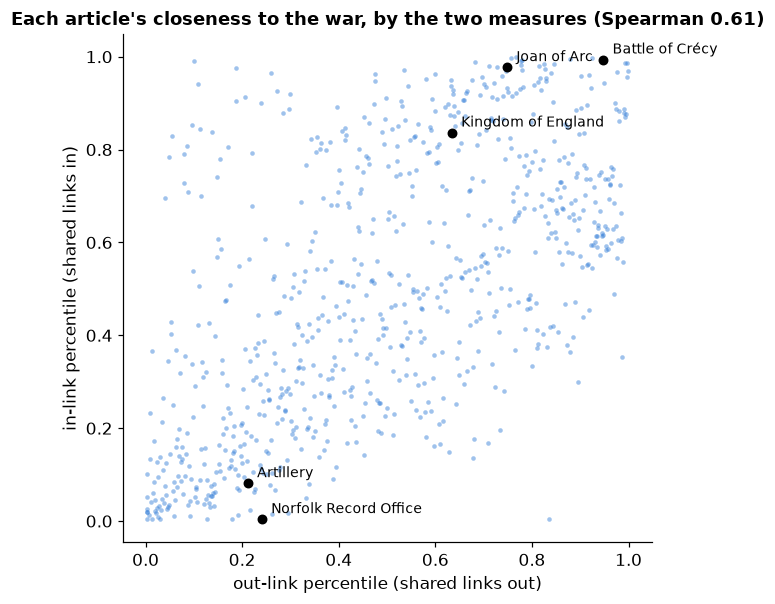

In [2]:
seed = pd.read_parquet(DATA / "seed_similarity.parquet").set_index("title")
n = len(seed)
x, y = 1 - seed["outlink_rank"] / n, 1 - seed["inlink_rank"] / n   # 1 = most similar to the war

fig, ax = plt.subplots(figsize=(6.2, 6))
ax.scatter(x, y, s=9, color=BLUE, alpha=0.45, linewidths=0)
for title in ["Battle of Crécy", "Kingdom of England", "Norfolk Record Office", "Artillery", "Joan of Arc"]:
    ax.annotate(title, (x[title], y[title]), xytext=(6, 4), textcoords="offset points", fontsize=9)
    ax.scatter(x[title], y[title], s=30, color="black")
rho = seed["outlink_rank"].corr(seed["inlink_rank"], method="spearman")
ax.set_title(f"Each article's closeness to the war, by the two measures (Spearman {rho:.2f})")
ax.set_xlabel("out-link percentile (shared links out)")
ax.set_ylabel("in-link percentile (shared links in)");

> ✏️ **[Your text]** Where do the two measures agree, and where do they disagree? Pick one or two labeled articles.

## Does how the war links to an article change its score?

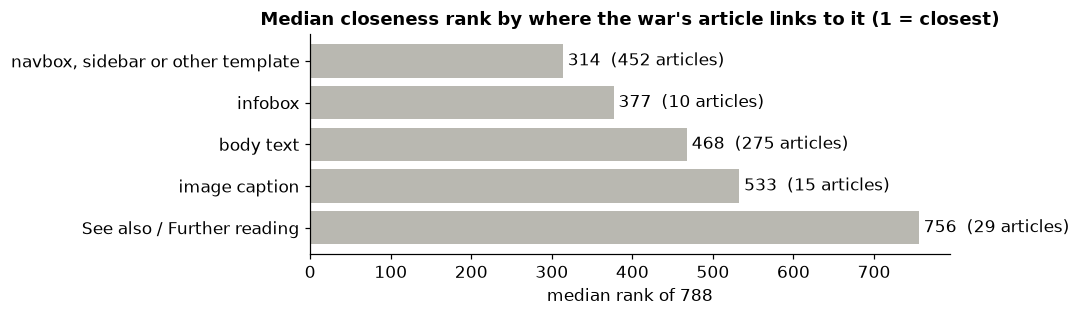

In [3]:
channels = pd.Series(json.loads((ROOT / "data" / "raw" / "link_channels" / "Hundred_Years_War.json").read_text())["channels"])
names = {"added by template": "navbox, sidebar or other template", "prose": "body text",
         "end section": "See also / Further reading", "caption": "image caption", "infobox": "infobox"}
by_channel = (seed[["milne_witten_rank"]].join(channels.rename("channel").map(lambda c: names.get(c, c)))
              .groupby("channel")["milne_witten_rank"].agg(["size", "median"]).sort_values("median"))
by_channel = by_channel[by_channel["size"] >= 10]

fig, ax = plt.subplots(figsize=(7.5, 2.6))
bars = ax.barh(by_channel.index[::-1], by_channel["median"][::-1], color=GRAY)
ax.bar_label(bars, labels=[f"{m:.0f}  ({int(s)} articles)" for s, m in by_channel[["size", "median"]].values[::-1]], padding=3)
ax.set_title("Median closeness rank by where the war's article links to it (1 = closest)")
ax.set_xlabel("median rank of 788");

> ✏️ **[Your text]** Navbox-linked articles look closer to the war than articles discussed in its text. Why? (Hint: a navbox puts the same links on every page it appears on.)

## Topic focus: how much of an article's own linking stays in this set

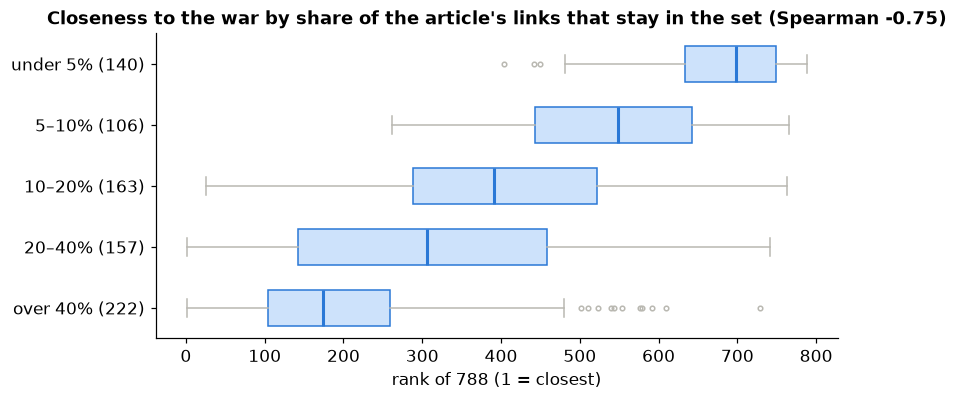

In [4]:
articles = pd.read_parquet(DATA / "articles.parquet").set_index("title")
focus = articles.loc[~articles.is_seed, ["pct_out_degree"]].join(seed["milne_witten_rank"])
bins = [0, 0.05, 0.1, 0.2, 0.4, 1.01]
names = ["under 5%", "5–10%", "10–20%", "20–40%", "over 40%"]
focus["bin"] = pd.cut(focus["pct_out_degree"], bins, labels=names, right=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([focus.loc[focus["bin"] == b, "milne_witten_rank"] for b in names][::-1], orientation="horizontal",
           widths=0.6, patch_artist=True, boxprops={"facecolor": "#cde2fb", "color": BLUE},
           medianprops={"color": BLUE, "linewidth": 2}, whiskerprops={"color": GRAY}, capprops={"color": GRAY},
           flierprops={"markersize": 3, "markeredgecolor": GRAY})
ax.set_yticks(range(1, len(names) + 1), [f"{b} ({(focus['bin'] == b).sum()})" for b in names][::-1])
rho = focus["pct_out_degree"].corr(focus["milne_witten_rank"], method="spearman")
ax.set_title(f"Closeness to the war by share of the article's links that stay in the set (Spearman {rho:.2f})")
ax.set_xlabel("rank of 788 (1 = closest)");

> ✏️ **[Your text]** Articles that link mostly to other articles here sit much closer to the war. How much of that is a finding, and how much is built in? (The out-link half of the measure counts these same links.)

---
**Full analysis, with all the code:** [02_milne_witten.ipynb](https://github.com/amos-johnson/hundred-years-war-similarity/blob/main/notebooks/02_milne_witten.ipynb)